# Lab 02 — CIFAR-10: EDA và Feature Engineering

Raw → kiểm tra dữ liệu → tiền xử lý → đặc trưng thủ công. [Báo cáo](../walkthrough_lab_02.md) · [Source EDA](../src/eda.py)

In [1]:
from pathlib import Path
import os, sys
ROOT = next(p for p in [Path(os.getenv('LAB02_ROOT', '.')).resolve(), *Path.cwd().resolve().parents] if (p / 'src/eda.py').exists())
sys.path.insert(0, str(ROOT))
from src import eda
OUT = eda.context(ROOT)
eda.overview(OUT)

,split,samples,shape,dtype,pixel_min,pixel_max,memory_mib
0,train,45000,32 x 32 x 3,uint8,0,255,131.84
1,val,5000,32 x 32 x 3,uint8,0,255,14.65
2,test,10000,32 x 32 x 3,uint8,0,255,29.30


## 1. Chất lượng ảnh raw

Kiểm tra checksum batch chính thức, nhãn, pixel hữu hạn, ảnh hằng và ảnh trùng byte trong/chéo các tập. Chỉ ghi nhận; giữ nguyên dữ liệu gốc.

In [2]:
eda.integrity_summary(OUT)

split,test,train,val
check,,,
constant_images,0,0,0
invalid_labels,0,0,0
nonfinite_pixels,0,0,0


,check,count
0,exact duplicate images across all partitions,0


## 2. Phân bố lớp và ảnh mẫu

Split stratified seed 42 được lưu một lần. Ảnh mẫu chỉ lấy từ train, kèm index gốc để truy vết.

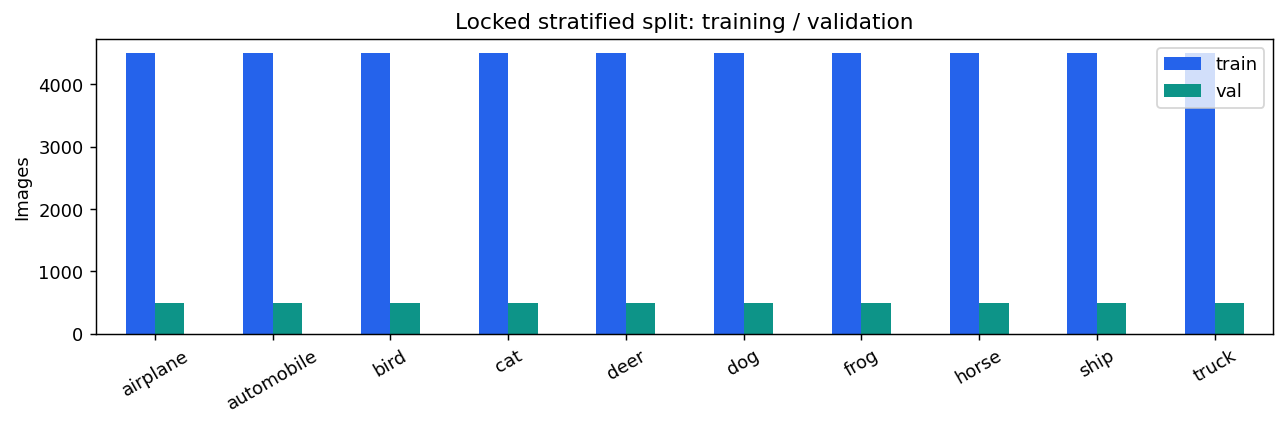

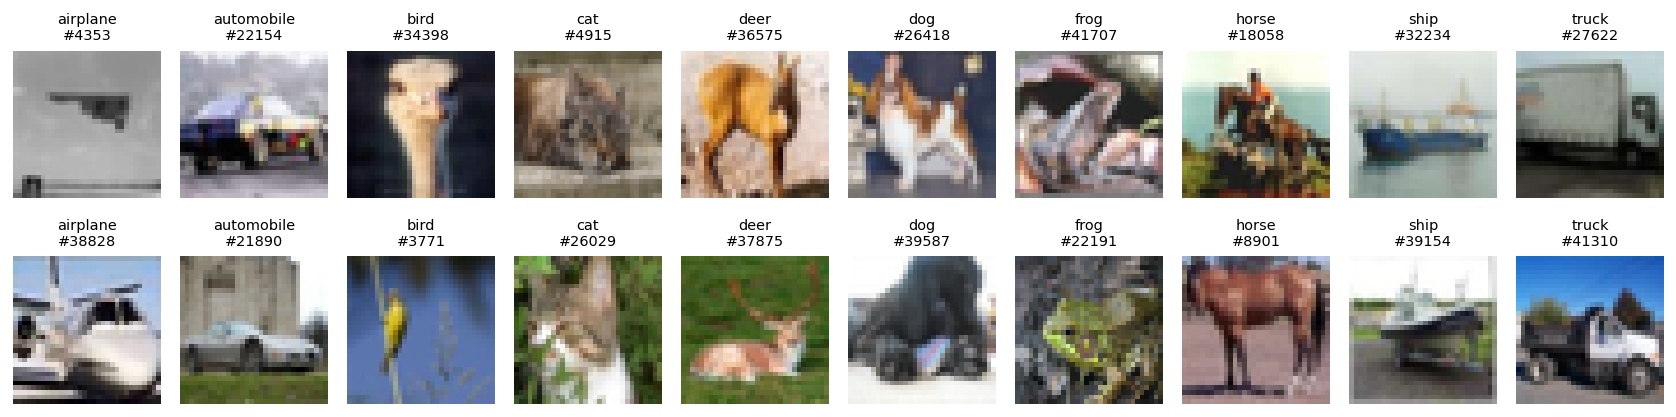

In [3]:
eda.gallery(OUT, 'class_distribution', 'sample_images')

## 3. Thống kê pixel và cấu trúc không gian

Histogram, mean/std và heatmap đo trên toàn bộ 45.000 ảnh train, không augmentation. Ảnh trung bình cho thấy bố cục và màu, không phải ảnh đại diện của một cá thể.

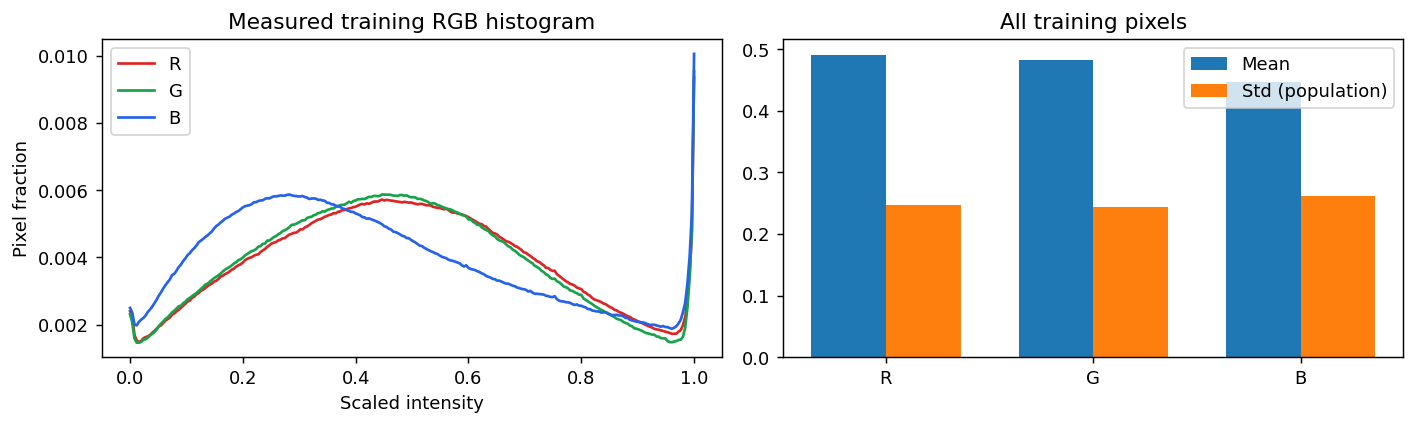

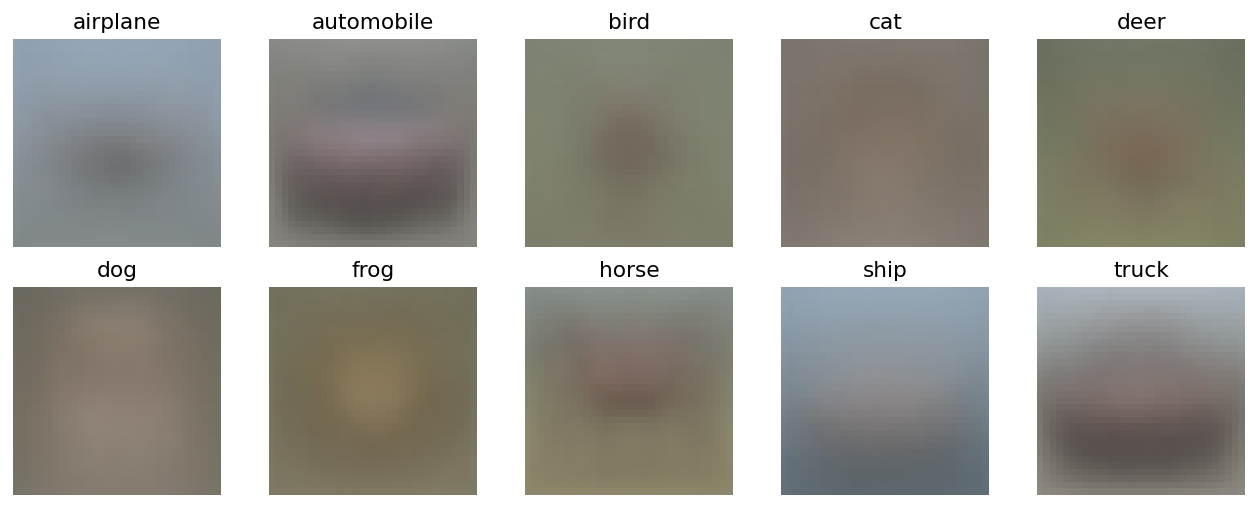

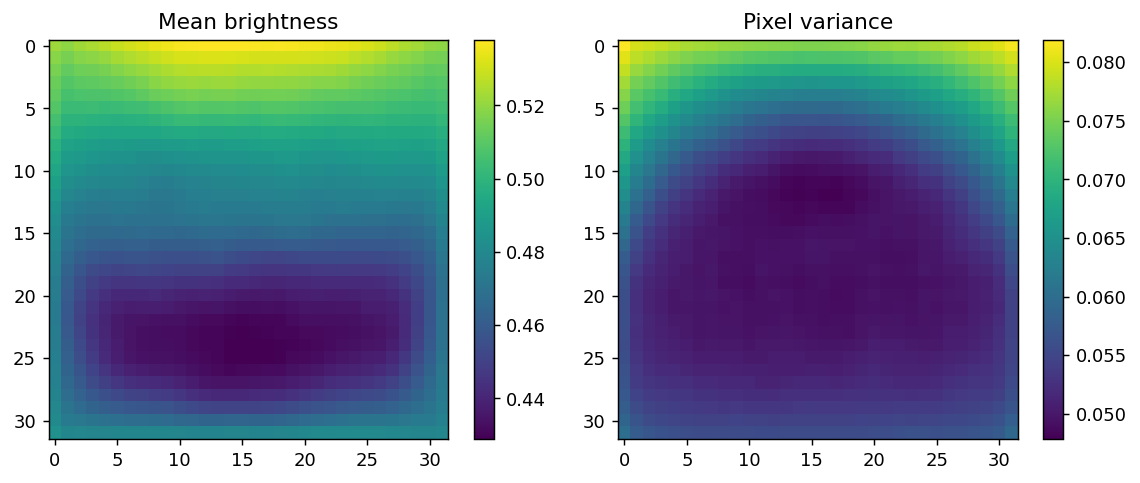

In [4]:
eda.gallery(OUT, 'pixel_statistics', 'class_mean_images', 'spatial_statistics')

## 4. Tiền xử lý

Giữ RGB; resize 64×64 → scale /255 → CHW → normalize. Histogram sau chuẩn hóa dùng pixel của ảnh minh họa thật; resize không thêm chi tiết. Mean/std ImageNet là hằng số của hợp đồng đầu vào, khác thống kê CIFAR-10 vừa đo.

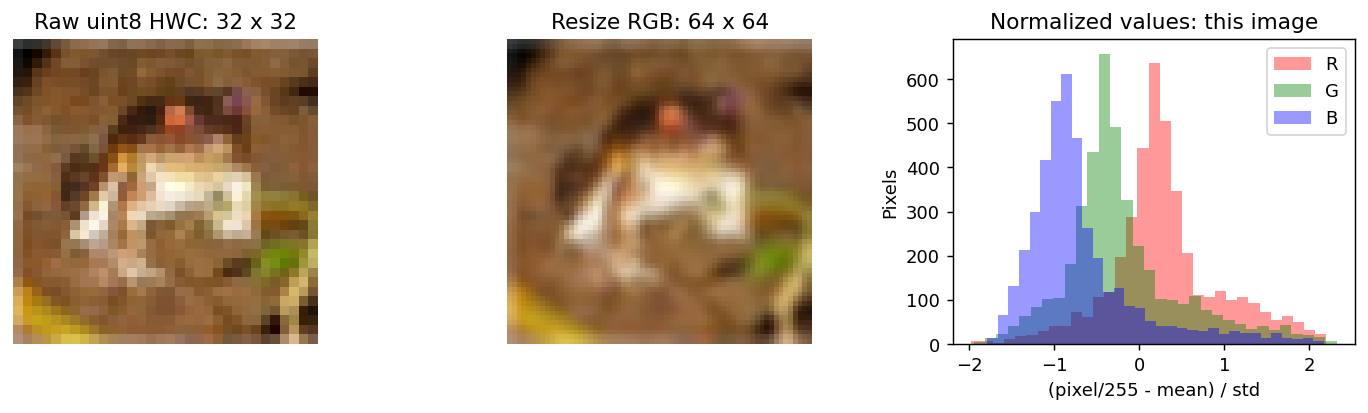

In [5]:
eda.gallery(OUT, 'preprocessing_preview')

## 5. Feature Engineering

Đặc trưng mô tả: độ sáng, tương phản, mean RGB, tỷ lệ pixel 0 và mật độ cạnh (ngưỡng gradient 0,1). Không có mask nên không suy diễn foreground/bounding box từ pixel đen. Các đặc trưng dùng để phân tích, không thay đổi tensor ảnh.

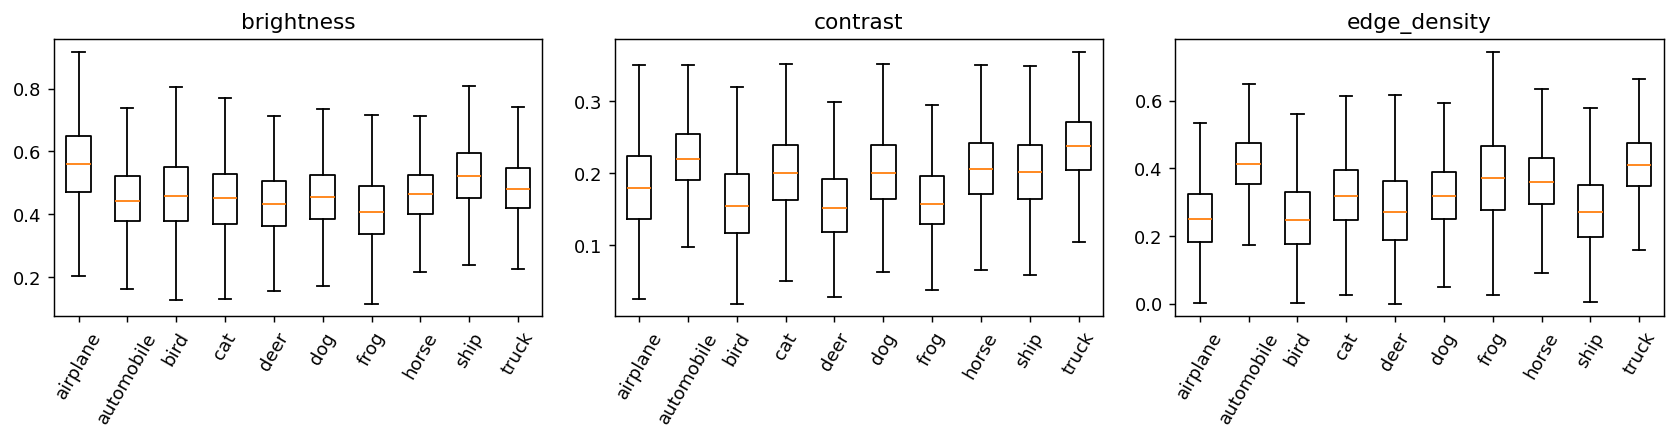

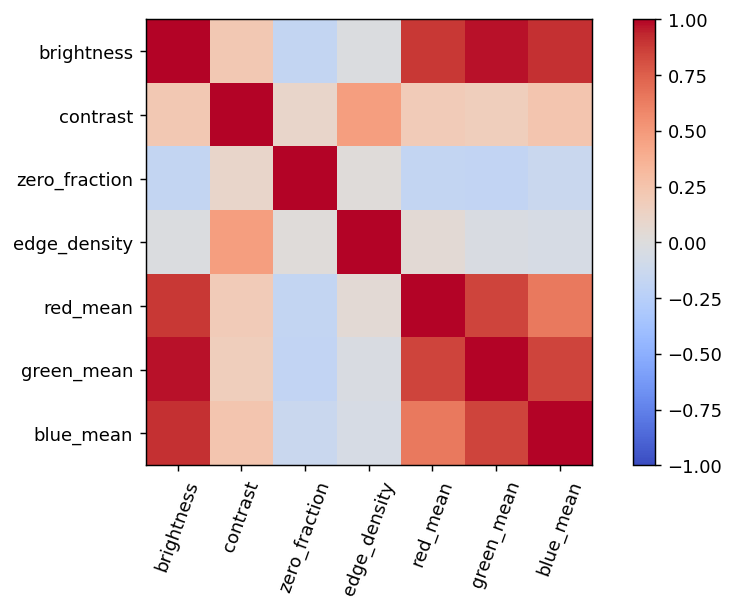

In [6]:
eda.gallery(OUT, 'handcrafted_distributions', 'feature_correlation')

## 6. Tương đồng giữa các lớp

Correlation giữa ảnh trung bình của các lớp chỉ mô tả hình dạng/màu trung bình; không phải thước đo khả năng phân loại.

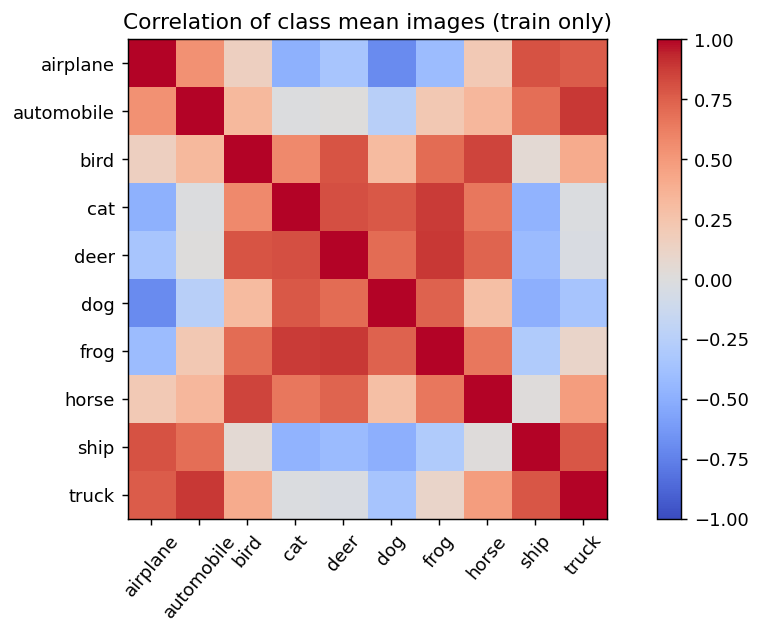

In [7]:
eda.gallery(OUT, 'class_similarity')

## 7. Bàn giao dữ liệu

Artifact tại `outputs/eda/`: split có hash/version, thống kê chỉ trên train và cấu hình tiền xử lý. Đọc [giới hạn và phát hiện](../walkthrough_lab_02.md#13-data-contract-and-partitioning-strategy).

In [8]:
eda.handoff(OUT)

,Contract,Value
0,Split,cifar10-stratified-42-45000-5000-v1
1,Preprocessing,rgb-resize64-imagenet-v1
2,Input,float32 CHW: 3 x 64 x 64
3,Normalization,ImageNet constants; measured train RGB statist...
4,Handcrafted features,"Brightness, contrast, RGB means, edge density:..."
5,Foreground / bounding box,not applicable: natural RGB images have no for...


Tái tính từ raw: `python scripts/analyze_data.py --data-dir <thư_mục_data>`. Notebook mặc định xem artifact đã đo; không cần weights hay checkpoint. [Bước tiếp theo](02_lab02_modeling.ipynb).